# Strategy A on the football graph (context on and off)

**Strategy A** asks the model directly for the hidden property of a `Player` node, with the 9 prompts of
Figure 2 (compact, zero-shot, 1/3/5-shot, each with and without chain of thought). 5 models, 3 runs each.
Two task sets: **context on** (`football-v1-ctx-idmix`, 239 tasks: the given properties G may include
properties of neighbouring nodes) and **context off** (`football-v1-noctx-idmix`, 233 tasks: G only from the
player). In the 81 high-G context-on tasks, the player's name and/or team were added to G with probability 0.38
(*identifier mix*), so the effect of the identifiers can be measured.

**Scoring.** Each task hides one property. The answer of a configuration (model, prompt or approach) is the vote over
its 3 runs (text: most frequent value; numbers: mean; abstained only when all 3 runs abstain), and is **correct**,
**wrong** or **abstained**. **F1** = 2c / (2c + 2w + a) counts abstentions against recall; **F1 (abstentions ignored)**
= 2c / (2c + w) scores only the answers given (the paper's Table 3 scoring). Intervals are 95% bootstrap intervals
over tasks (1,000 resamples); paired differences resample the same tasks for both sides; task-by-task comparisons use
an exact McNemar test on "correct".

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"))
from paper_report_lib import *
FOLDER = "football_a"

v = load_voted(("football", "ctx"), ("football", "noctx"))
A = v[v.strategy == "A"].copy()
runs = load_runs(("football", "ctx"), ("football", "noctx"))
runsA = runs[runs.strategy == "A"]
eff = load_effort()
effA = eff[(eff.dataset == "football") & (eff.strategy == "A")]
print(A.groupby("set").task_id.nunique().to_dict(), "tasks;", len(A), "voted rows;", len(runsA), "scored runs")

{'ctx': 239, 'noctx': 233} tasks; 21240 voted rows; 63720 scored runs


## 1. Overall results

### Scores per model and set, all 9 prompts pooled, and each model's best prompt

In [2]:
pool = boot(A, ["set", "mname"])
display(pool[["set", "mname", "tasks", "correct", "wrong", "abstained", "precision", "recall", "f1", "f1_lo", "f1_hi",
              "f1_ign", "f1_ign_lo", "f1_ign_hi", "abstention"]])
mp = metrics(A, ["set", "mname", "approach"])
best = pd.concat([mp.loc[mp.groupby(["set", "mname"])[s].idxmax(), ["set", "mname", "approach", s]].rename(
    columns={"approach": f"best prompt ({n})", s: n}).set_index(["set", "mname"]) for s, n in SCORES], axis=1)
display(best)

,set,mname,tasks,correct,wrong,abstained,precision,recall,f1,f1_lo,f1_hi,f1_ign,f1_ign_lo,f1_ign_hi,abstention
0,ctx,deepseek-v4.1-flash,2151,710,879,562,0.447,0.330,0.380,0.358,0.402,0.618,0.594,0.642,0.261
1,ctx,gemma4:31b,2151,171,219,1761,0.438,0.079,0.135,0.116,0.154,0.610,0.557,0.657,0.819
2,ctx,gpt-oss:120b,2151,130,187,1834,0.410,0.060,0.105,0.088,0.122,0.582,0.527,0.635,0.853
3,ctx,gpt-oss:20b,2151,225,294,1632,0.434,0.105,0.169,0.149,0.188,0.605,0.564,0.646,0.759
4,ctx,mistral-large-3,2151,607,932,612,0.394,0.282,0.329,0.308,0.350,0.566,0.542,0.590,0.285
5,noctx,deepseek-v4.1-flash,2097,677,858,562,0.441,0.323,0.373,0.351,0.394,0.612,0.587,0.636,0.268
6,noctx,gemma4:31b,2097,135,200,1762,0.403,0.064,0.111,0.094,0.128,0.574,0.519,0.629,0.840
7,noctx,gpt-oss:120b,2097,129,183,1785,0.413,0.062,0.107,0.091,0.125,0.585,0.532,0.639,0.851
8,noctx,gpt-oss:20b,2097,229,274,1594,0.455,0.109,0.176,0.157,0.195,0.626,0.585,0.666,0.760
9,noctx,mistral-large-3,2097,583,898,616,0.394,0.278,0.326,0.306,0.348,0.565,0.539,0.590,0.294


best prompt (F1)    F1 best prompt (F1 (abstentions ignored))  F1 (abstentions ignored)
set   mname                                                                                                      
ctx   deepseek-v4.1-flash            few_3 0.428                                  few_5                     0.636
      gemma4:31b                   compact 0.292                               fewcot_3                     0.743
      gpt-oss:120b                 compact 0.185                                  few_5                     0.800
      gpt-oss:20b                  compact 0.250                               fewcot_3                     0.771
      mistral-large-3                few_5 0.413                                  few_5                     0.654
noctx deepseek-v4.1-flash            few_5 0.436                                  few_5                     0.655
      gemma4:31b                   compact 0.293                                  few_1                     0.650
      gpt-oss:120b                 compact 0.194                                  few_5                     0.809
      gpt-oss:20b                  compact 0.265                                  few_3                     0.800
      mistral-large-3                few_5 0.424                                  few_5                     0.664

Pooled over the 9 prompts, two groups of models appear on football. **deepseek-v4.1-flash** (F1 0.38) and **mistral-large-3** (0.33) answer most tasks, abstaining on 26–29%. **gpt-oss:20b**, **gemma4:31b** and **gpt-oss:120b** (F1 0.11–0.17) abstain on 76–85%. With abstentions ignored the five models are within 0.05 of each other (F1 ign 0.57–0.62). So on football the ranking by F1 measures willingness to answer more than knowledge. The best prompt by F1 is **compact** for the three cautious models and few-shot (3 or 5 examples) for deepseek and mistral.

### F1 per model, context on vs off (9 prompts pooled)

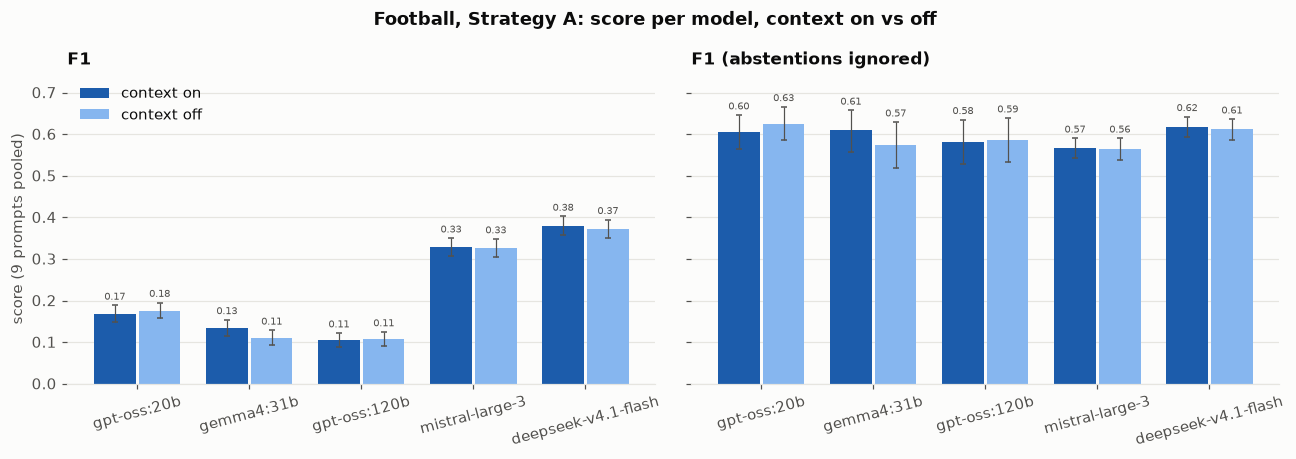

In [3]:
t = boot(A, ["set", "model"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (s, n) in zip(axes, SCORES):
    grouped_bars(ax, t, "model", MODELS, "set", ["ctx", "noctx"], s, SCOLOR, names={**MNAME, "ctx": "context on", "noctx": "context off"})
    ax.set_title(n); ax.set_xticklabels(MN, rotation=15)
axes[0].set_ylabel("score (9 prompts pooled)"); axes[0].legend(loc="upper left")
fig.suptitle("Football, Strategy A: score per model, context on vs off")
save(fig, FOLDER, "a_pooled_by_model")

Context on and context off give almost the same pooled scores for every model: F1 differs by at most 0.02 and F1 ign by at most 0.04, all within the 95% intervals. This is expected from the design. 200 of the 233 context-off tasks are identical to their context-on version, so the two sets differ only in the 33 tasks whose given properties include context properties (section 3).

### F1 per model and prompt, context on

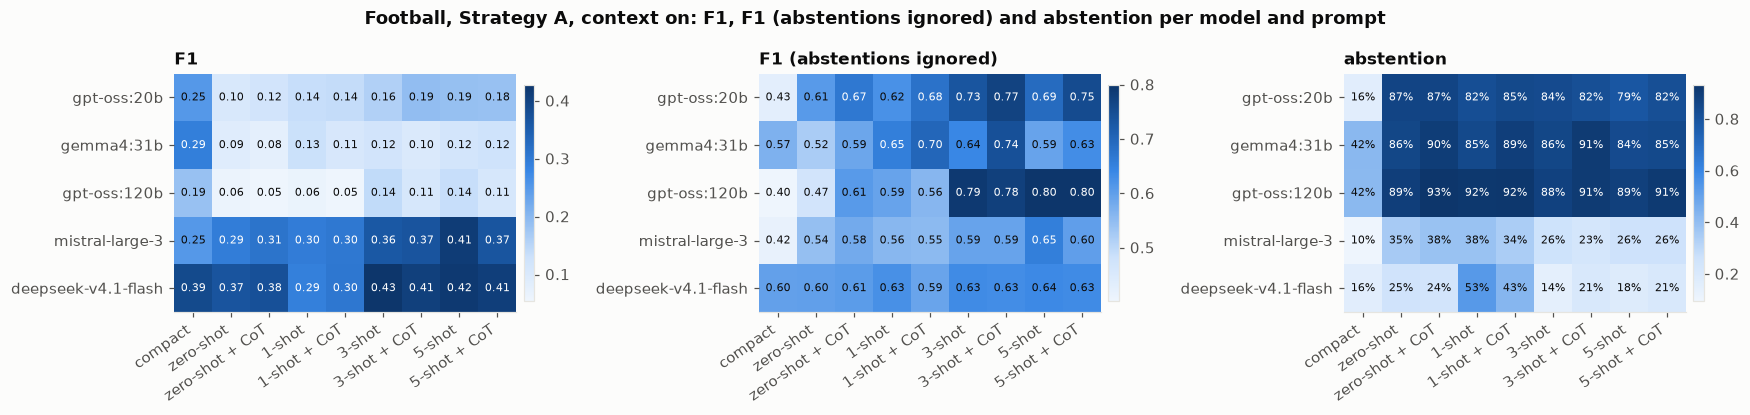

In [4]:
t = metrics(A[A.set == "ctx"], ["model", "approach"])
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (s, n) in zip(axes, SCORES + [("abstention", "abstention")]):
    pv = t.pivot(index="model", columns="approach", values=s).reindex(index=MODELS, columns=PROMPTS)
    heat(ax, pv, fmt="{:.0%}" if s == "abstention" else "{:.2f}", xlabels=[PNAME[p] for p in PROMPTS], ylabels=MN)
    ax.set_title(n)
fig.suptitle("Football, Strategy A, context on: F1, F1 (abstentions ignored) and abstention per model and prompt")
save(fig, FOLDER, "a_heat_ctx")

The heatmaps show the trade-off that drives F1 on football. The **compact** prompt nearly removes abstention for the cautious models (gpt-oss:20b from 79–87% to 16%; gemma4 and gpt-oss:120b from 84–93% to 42%). This raises their F1 to their best value but gives their lowest F1 ign (0.40–0.57), because the extra answers are mostly wrong. For gpt-oss:120b the opposite holds with examples: 3- and 5-shot prompts reach F1 ign 0.78–0.80 while still abstaining on about 90% of the tasks. deepseek is the most stable across prompts (F1 0.29–0.43, F1 ign 0.59–0.64).

### F1 per model and prompt, context off

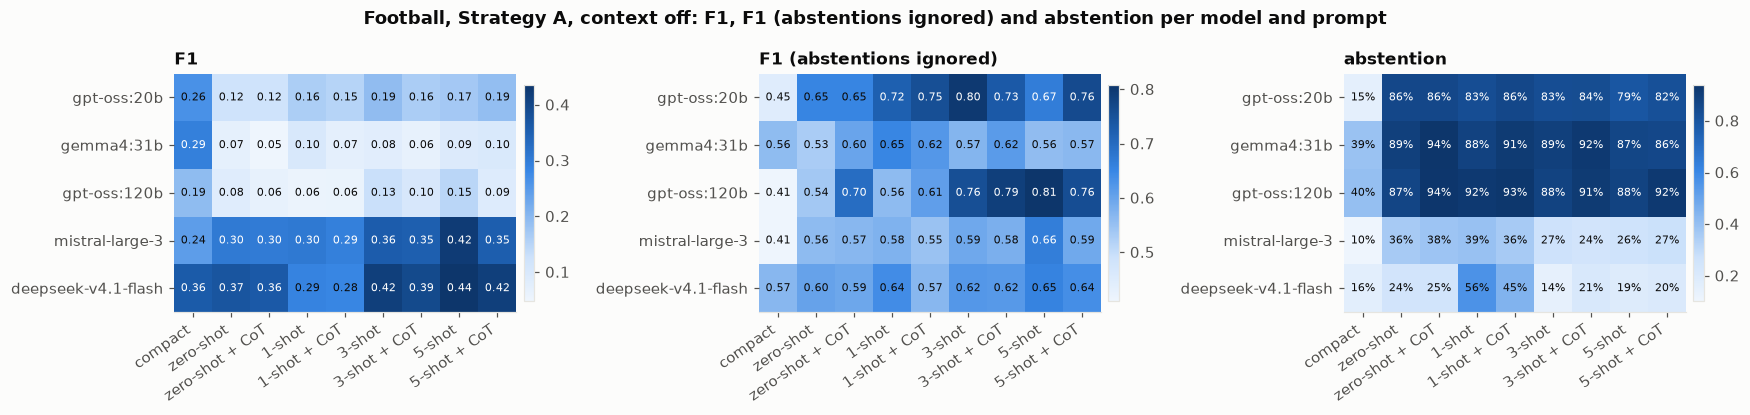

In [5]:
t = metrics(A[A.set == "noctx"], ["model", "approach"])
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (s, n) in zip(axes, SCORES + [("abstention", "abstention")]):
    pv = t.pivot(index="model", columns="approach", values=s).reindex(index=MODELS, columns=PROMPTS)
    heat(ax, pv, fmt="{:.0%}" if s == "abstention" else "{:.2f}", xlabels=[PNAME[p] for p in PROMPTS], ylabels=MN)
    ax.set_title(n)
fig.suptitle("Football, Strategy A, context off: F1, F1 (abstentions ignored) and abstention per model and prompt")
save(fig, FOLDER, "a_heat_noctx")

Without context the pattern is the same: compact is the best prompt by F1 for the three cautious models, few-shot for deepseek and mistral. The values move by a few hundredths at most, as expected from 200 identical tasks.

### Outcomes per model and prompt, context on

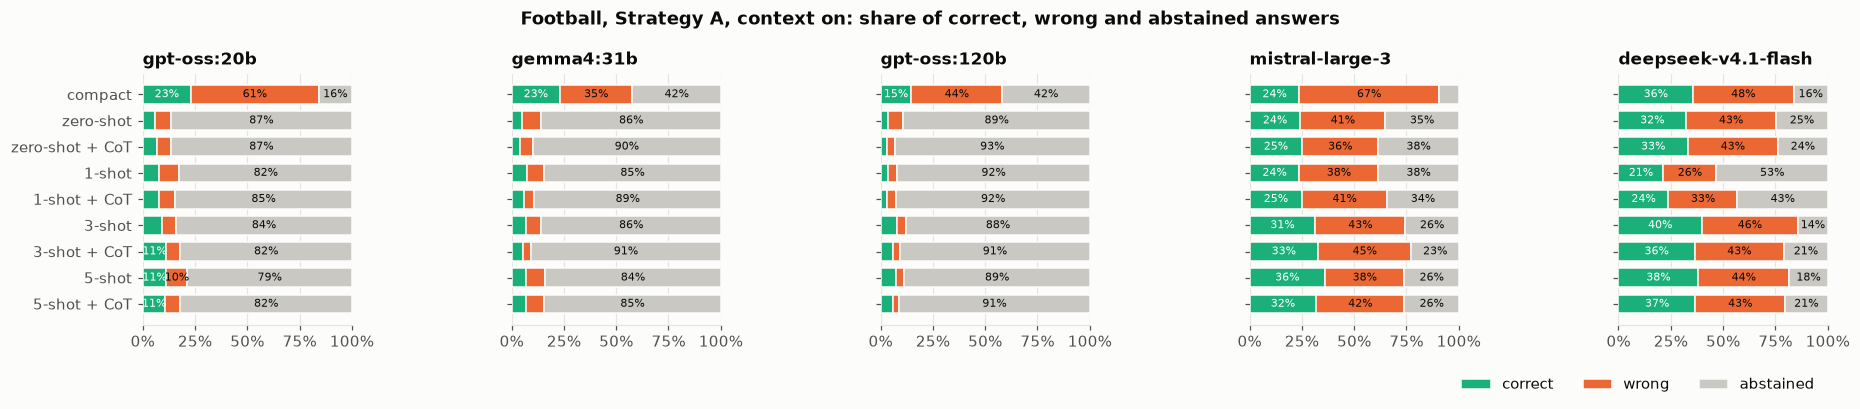

In [6]:
t = metrics(A[A.set == "ctx"], ["model", "approach"])
fig, axes = plt.subplots(1, 5, figsize=(17, 4), sharey=True)
for ax, m in zip(axes, MODELS):
    stacked_outcomes(ax, t[t.model == m], "approach", PROMPTS, names=PNAME)
    ax.set_title(MNAME[m])
axes[-1].legend(loc="lower right", bbox_to_anchor=(1, -0.32), ncol=3)
fig.suptitle("Football, Strategy A, context on: share of correct, wrong and abstained answers")
save(fig, FOLDER, "a_outcomes_ctx")

The stacked bars make the abstention behaviour explicit. Under every prompt except compact, gpt-oss:20b, gemma4 and gpt-oss:120b leave 79–93% of the properties empty, and the few answers they give are right about as often as they are wrong. mistral and deepseek answer 47–90% of the tasks under every prompt, with 1.06–1.4 wrong answers per right one (2.8 for mistral with the compact prompt). Their higher F1 comes from recall, not precision.

### Precision against recall, every model and prompt

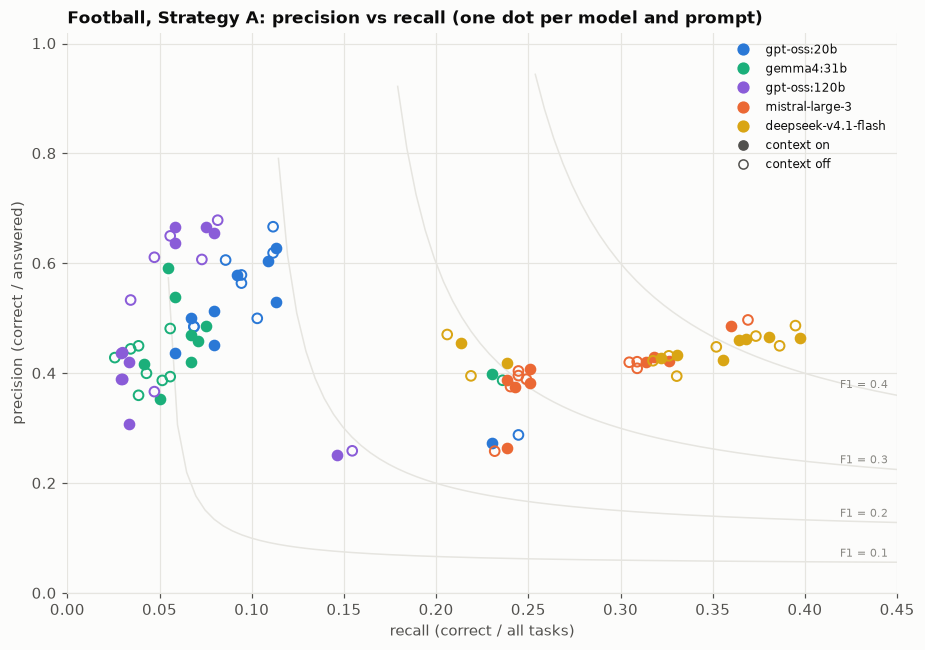

In [7]:
t = metrics(A, ["set", "model", "approach"])
fig, ax = plt.subplots(figsize=(8.5, 6))
rr = np.linspace(0.01, 1, 200)
for f in (0.1, 0.2, 0.3, 0.4):
    p_ = f * rr / (2 * rr - f); ok = (p_ > 0) & (p_ <= 1)
    ax.plot(rr[ok], p_[ok], color=GRID, lw=1, zorder=1); ax.text(0.445, f * 0.445 / (0.89 - f) + 0.01, f"F1 = {f}", fontsize=7, color=MUTED, ha="right")
for m in MODELS:
    for s_, fc in (("ctx", MCOLOR[m]), ("noctx", "none")):
        d = t[(t.model == m) & (t.set == s_)]
        ax.scatter(d.recall, d.precision, s=40, facecolor=fc, edgecolor=MCOLOR[m], linewidth=1.3, zorder=3)
ax.set_xlabel("recall (correct / all tasks)"); ax.set_ylabel("precision (correct / answered)"); ax.set_xlim(0, 0.45); ax.set_ylim(0, 1.02)
h = model_handles() + [plt.Line2D([], [], ls="", marker="o", color=INK2, label="context on"),
                       plt.Line2D([], [], ls="", marker="o", mfc="none", color=INK2, label="context off")]
ax.legend(handles=h, loc="upper right", fontsize=8)
ax.set_title("Football, Strategy A: precision vs recall (one dot per model and prompt)")
save(fig, FOLDER, "a_precision_recall")

In precision–recall space the 90 model × prompt points form two clusters. The cautious models sit at recall 0.03–0.12 under every prompt except compact, with precision 0.25–0.67. deepseek and mistral sit at recall 0.21–0.40 with precision 0.26–0.49. Only the compact prompt moves a cautious model into the high-recall region (recall 0.15–0.23), at a precision of 0.25–0.40. Context on (filled) and off (hollow) points overlap almost everywhere.

## 2. Prompts

### Effect of the number of examples and of chain of thought (context on)

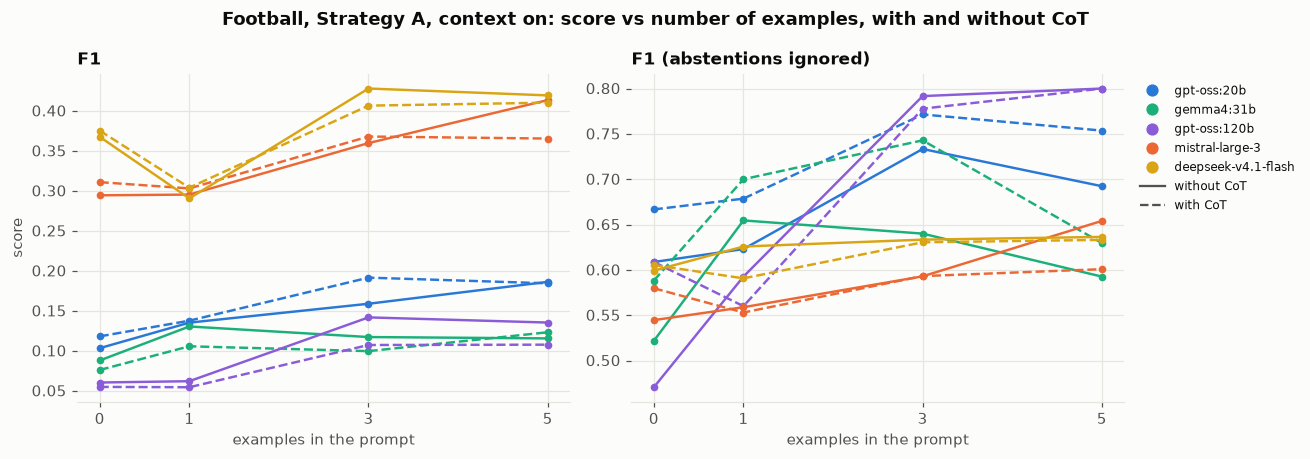

In [8]:
t = metrics(A[(A.set == "ctx") & (A.approach != "compact")], ["model", "approach"])
t["shots"] = t.approach.map(SHOTS); t["cot"] = t.approach.str.contains("cot")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, (s, n) in zip(axes, SCORES):
    for m in MODELS:
        for cot, ls in ((False, "-"), (True, "--")):
            d = t[(t.model == m) & (t.cot == cot)].sort_values("shots")
            ax.plot(d.shots, d[s], ls=ls, marker="o", ms=4, color=MCOLOR[m], lw=1.6)
    ax.set_xticks([0, 1, 3, 5]); ax.set_xlabel("examples in the prompt"); ax.set_title(n)
axes[0].set_ylabel("score")
axes[1].legend(handles=model_handles() + [plt.Line2D([], [], color=INK2, label="without CoT"),
                                          plt.Line2D([], [], color=INK2, ls="--", label="with CoT")], fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("Football, Strategy A, context on: score vs number of examples, with and without CoT")
save(fig, FOLDER, "a_shots_cot")

Examples help, with diminishing returns after 3. From zero-shot to 3-shot, F1 grows for every model (largest for deepseek: 0.37 → 0.43), and F1 ign grows by 0.10–0.32 for gpt-oss:120b and gpt-oss:20b. Going from 3 to 5 examples changes F1 by at most ±0.05. Chain of thought gives no consistent gain: the dashed and solid lines cross for every model.

### Prompt ranking across models

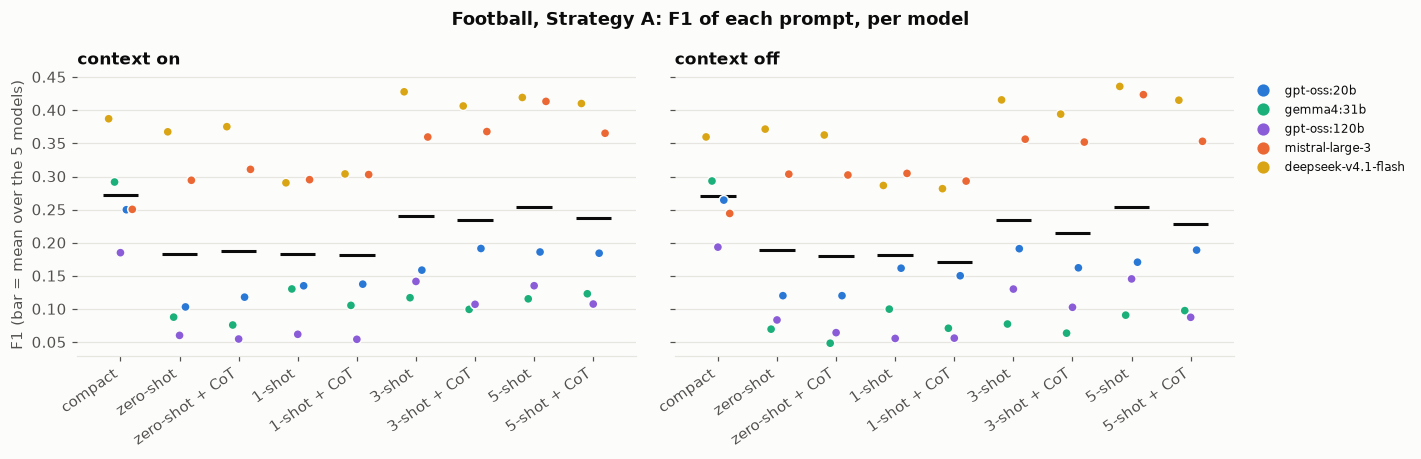

set,"mean rank, on","mean rank, off"
approach,,
compact,3.400,3.800
zero,7.800,6.500
zerocot,7.200,7.500
few_1,6.200,6.000
fewcot_1,7.000,7.600
few_3,3.200,2.800
fewcot_3,4.000,5.000
few_5,2.800,2.400
fewcot_5,3.400,3.400


In [9]:
t = metrics(A, ["set", "model", "approach"])
t["rank"] = t.groupby(["set", "model"]).f1.rank(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, s_ in zip(axes, ["ctx", "noctx"]):
    d = t[t.set == s_]
    for j, p in enumerate(PROMPTS):
        dd = d[d.approach == p]
        ax.scatter(np.full(len(dd), j) + np.linspace(-0.2, 0.2, len(dd)), dd.f1, c=[MCOLOR[m] for m in dd.model], s=36, zorder=3, edgecolor=SURFACE)
        ax.hlines(dd.f1.mean(), j - 0.3, j + 0.3, color=INK, lw=2)
    ax.set_xticks(range(len(PROMPTS))); ax.set_xticklabels([PNAME[p] for p in PROMPTS], rotation=35, ha="right")
    ax.set_title("context " + ("on" if s_ == "ctx" else "off")); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("F1 (bar = mean over the 5 models)"); axes[1].legend(handles=model_handles(), fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("Football, Strategy A: F1 of each prompt, per model")
save(fig, FOLDER, "a_prompt_rank")
display(t.pivot_table(index="approach", columns="set", values="rank").reindex(PROMPTS).rename(columns={"ctx": "mean rank, on", "noctx": "mean rank, off"}))

Averaged over the five models, 5-shot (mean rank 2.8 on, 2.4 off) and 3-shot (3.2 / 2.8) are the best prompts on football, followed by compact and 5-shot + CoT (3.4). Zero-shot is the worst (7.8 / 6.5). The spread between models inside each prompt is much larger than the spread between prompt means, which is the model-over-prompt effect seen on airports.

## 3. Context on vs off

### Paired effect of context (task pairs whose context differs, voted answers)

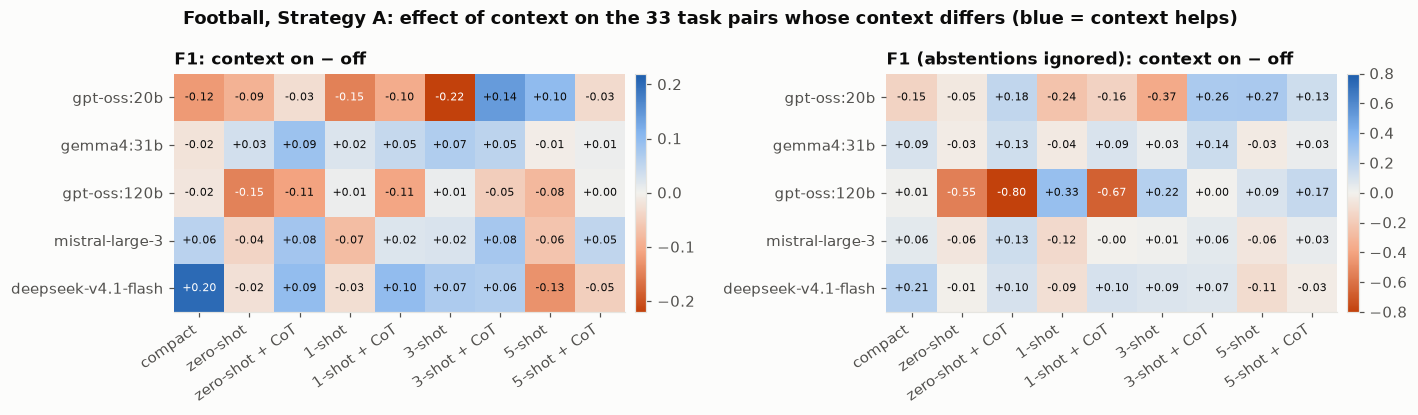

model × prompt cells with a 95% interval excluding 0: {'f1': 3, 'f1_ign': 1} of 45


,model,ΔF1,ΔF1 (abstentions ignored)
0,gpt-oss:20b,"-0.055 [-0.118, +0.015]","-0.020 [-0.150, +0.116]"
1,gemma4:31b,"+0.026 [-0.016, +0.068]","+0.032 [-0.039, +0.104]"
2,gpt-oss:120b,"-0.052 [-0.106, -0.002]","+0.005 [-0.160, +0.155]"
3,mistral-large-3,"+0.015 [-0.035, +0.064]","+0.006 [-0.058, +0.068]"
4,deepseek-v4.1-flash,"+0.033 [-0.015, +0.078]","+0.036 [-0.012, +0.082]"
5,all models,"+0.002 [-0.022, +0.025]","+0.018 [-0.015, +0.051]"


In [10]:
rows = []
pairs = context_pairs("football")   # context-off task -> context-on task, only pairs whose G differs
off = A[A.set == "noctx"].assign(task_id=lambda x: x.task_id.map(pairs)).dropna(subset=["task_id"])
on = A[(A.set == "ctx") & A.task_id.isin(pairs.values())]
for m in MODELS:
    for p in PROMPTS:
        x = off[(off.model == m) & (off.approach == p)].set_index("task_id").outcome
        y = on[(on.model == m) & (on.approach == p)].set_index("task_id").outcome
        for s, n in SCORES:
            d, lo, hi = paired_diff(x, y, s)
            rows.append({"model": m, "approach": p, "score": s, "diff": d, "lo": lo, "hi": hi, "significant": lo > 0 or hi < 0})
pdf = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (s, n) in zip(axes, SCORES):
    pv = pdf[pdf.score == s].pivot(index="model", columns="approach", values="diff").reindex(index=MODELS, columns=PROMPTS)
    heat(ax, pv, fmt="{:+.2f}", cmap=DIV, center=0, xlabels=[PNAME[p] for p in PROMPTS], ylabels=MN)
    ax.set_title(f"{n}: context on − off")
fig.suptitle(f"Football, Strategy A: effect of context on the {len(pairs)} task pairs whose context differs (blue = context helps)")
save(fig, FOLDER, "a_context_effect")
print("model × prompt cells with a 95% interval excluding 0:", pdf.groupby("score").significant.sum().to_dict(), "of", len(MODELS) * len(PROMPTS))
pooled = []
for m in MODELS + [None]:
    x = off[(off.model == m) if m else off.model.notna()].set_index(["task_id", "model", "approach"]).outcome
    y = on[(on.model == m) if m else on.model.notna()].set_index(["task_id", "model", "approach"]).outcome
    r = {"model": MNAME.get(m, "all models")}
    for s, n in SCORES:
        d, lo, hi = paired_diff(x, y, s); r[f"Δ{n}"] = f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]"
    pooled.append(r)
display(pd.DataFrame(pooled))

On the 33 task pairs whose context-on version replaces some of the player's own properties with properties of neighbouring nodes, context makes no measurable difference. Pooled over models and prompts, F1 on − off is +0.002 [−0.022, +0.025] and F1 ign +0.018 [−0.015, +0.051]. Only 3 of 45 model × prompt cells for F1, and 1 for F1 ign, have an interval that excludes 0, which is about what chance gives at 95%.

## 4. Task factors

### Score per stratum (context on, 9 prompts pooled)

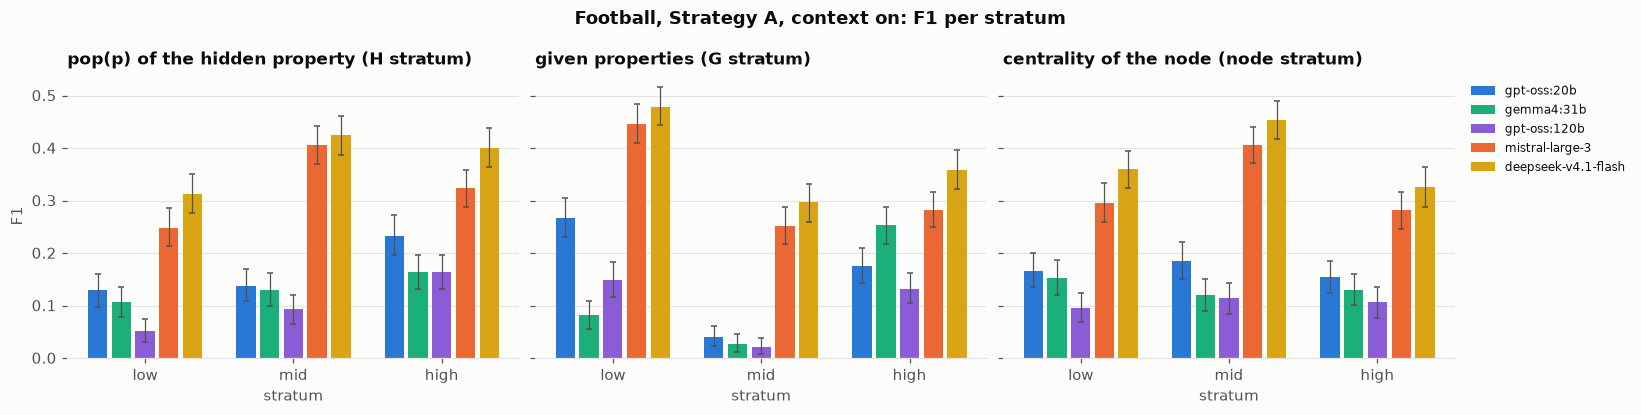

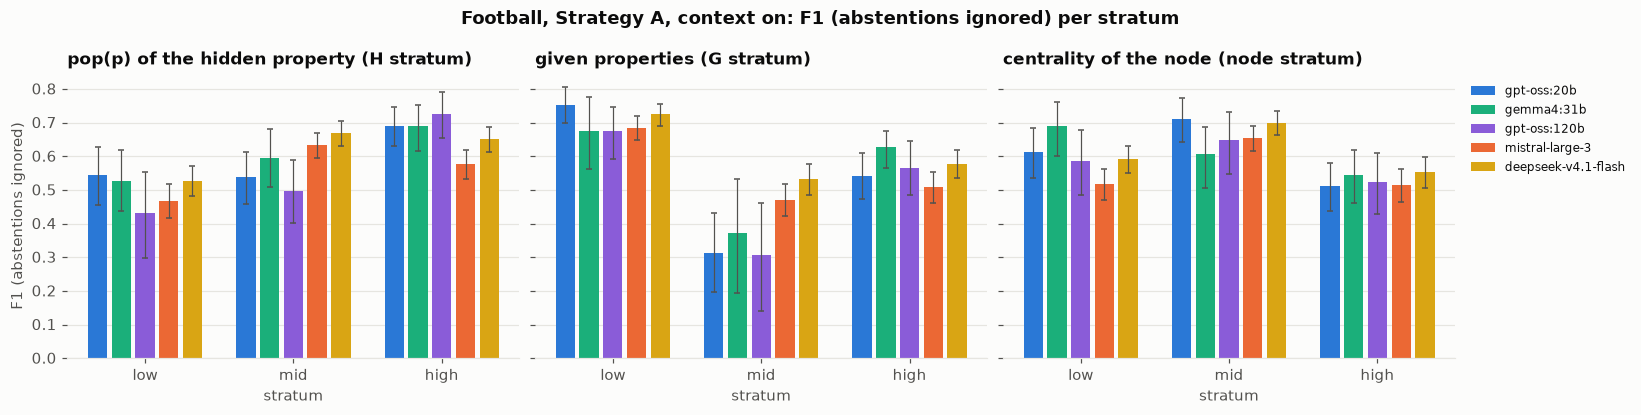

In [11]:
for s, n in SCORES:
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
    for ax, (f, fn) in zip(axes, FACTORS.items()):
        t = boot(A[A.set == "ctx"], ["model", f])
        grouped_bars(ax, t, f, STRATA, "model", MODELS, s, MCOLOR, names=MNAME, labels=False)
        ax.set_title(fn); ax.set_xlabel("stratum")
    axes[0].set_ylabel(n); axes[-1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.suptitle(f"Football, Strategy A, context on: {n} per stratum")
    save(fig, FOLDER, f"a_strata_{s}")

The strata defined on airports do not order the football tasks in the same way. By the popularity of the hidden property (H), high- and mid-popularity properties score higher than low ones for every model, as on airports. By the given properties (G), the **low** stratum scores highest (deepseek and mistral F1 0.45–0.48) and mid the lowest. By node centrality there is no monotone trend. The G result reflects which properties fall in each stratum (next chart) rather than a property of the graph.

### Score against task difficulty (context on, tertiles)

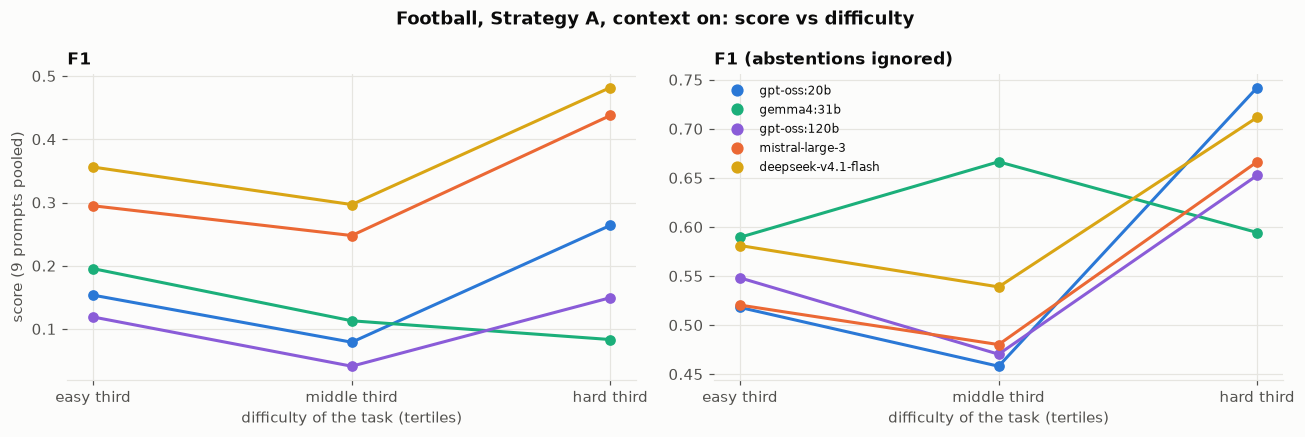

In [12]:
d = A[A.set == "ctx"].copy()
d["difficulty bin"] = pd.qcut(d.difficulty, 3, labels=["easy third", "middle third", "hard third"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, (s, n) in zip(axes, SCORES):
    t = metrics(d, ["model", "difficulty bin"])
    for m in MODELS:
        tt = t[t.model == m].set_index("difficulty bin").reindex(["easy third", "middle third", "hard third"])
        ax.plot(tt.index.astype(str), tt[s], marker="o", color=MCOLOR[m], lw=2)
    ax.set_title(n); ax.set_xlabel("difficulty of the task (tertiles)")
axes[0].set_ylabel("score (9 prompts pooled)"); axes[1].legend(handles=model_handles(), fontsize=8)
fig.suptitle("Football, Strategy A, context on: score vs difficulty")
save(fig, FOLDER, "a_difficulty")

Score does not fall with the difficulty score on football: the hardest tertile has the highest F1 and F1 ign for four of five models. 69 of the 81 hardest tasks are low-G tasks, and their hidden properties include easy-to-guess numbers like *Minutes per start* (truth 61–90, median 88), where any value near 85 passes the numeric tolerance (similarity ≥ 0.75). Removing *Minutes per start* lowers every tertile but keeps the order. The difficulty formula, which was built from popularity and centrality, therefore does not transfer to football as a predictor of difficulty.

### Name and team of the player in the given properties (high-G tasks, context on)

condition  team  none  name  both
tasks        31    22    16    12


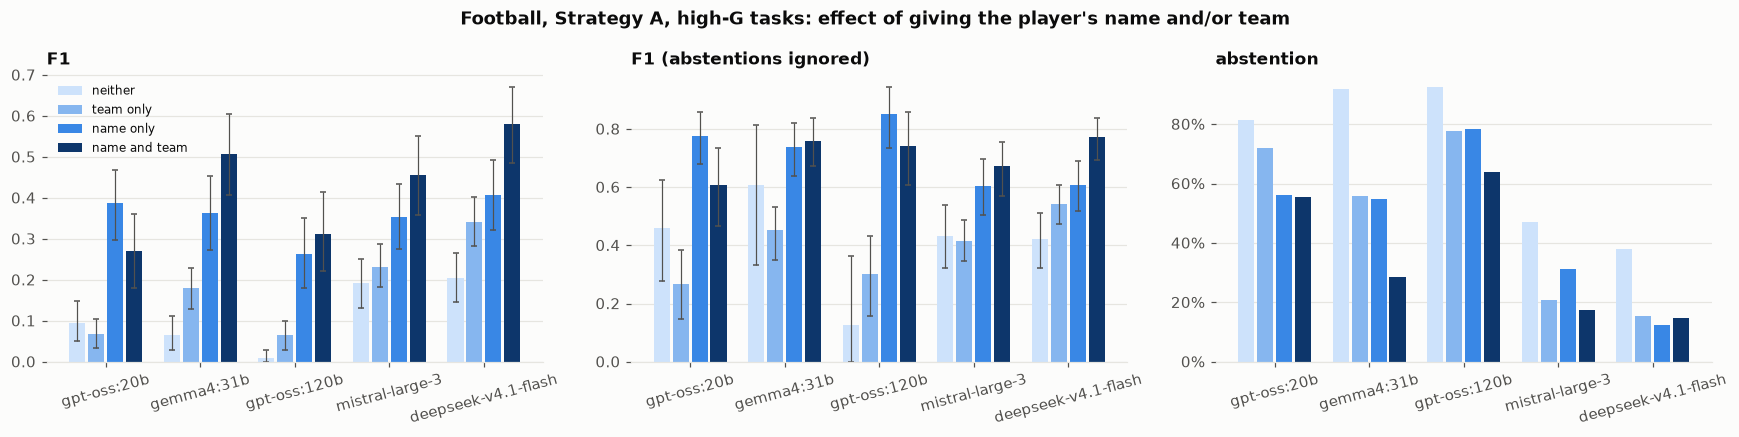

In [13]:
d = A[(A.set == "ctx") & (A.G_stratum == "high")]
conds = ["none", "team", "name", "both"]
CN = {"none": "neither", "team": "team only", "name": "name only", "both": "name and team"}
CC = dict(zip(conds, ["#cde2fb", "#86b6ef", "#3987e5", "#0d366b"]))
t = boot(d, ["model", "condition"])
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (s, n) in zip(axes, SCORES + [("abstention", "abstention")]):
    grouped_bars(ax, t, "model", MODELS, "condition", conds, s, CC, names={**MNAME, **CN}, err=s != "abstention", labels=False)
    ax.set_title(n); ax.set_xticklabels(MN, rotation=15)
axes[0].legend(fontsize=8); pct(axes[2])
print(d.drop_duplicates("task_id").condition.value_counts().rename("tasks").to_frame().T)
fig.suptitle("Football, Strategy A, high-G tasks: effect of giving the player's name and/or team")
save(fig, FOLDER, "a_identifiers")

The player's name is the strongest single factor on football. In the 81 high-G tasks, giving the name raises F1 for every model, e.g. gpt-oss:20b from 0.09 to 0.39, gemma4 from 0.07 to 0.36–0.51 and deepseek from 0.21 to 0.41–0.58. Pooled over models and prompts, F1 goes from 0.17 without a name to 0.40 with one, F1 ign from 0.44 to 0.70, and abstention falls from 57% to 42%. The team alone helps less and not for every model.

### Score per hidden property (context on, 9 prompts pooled)

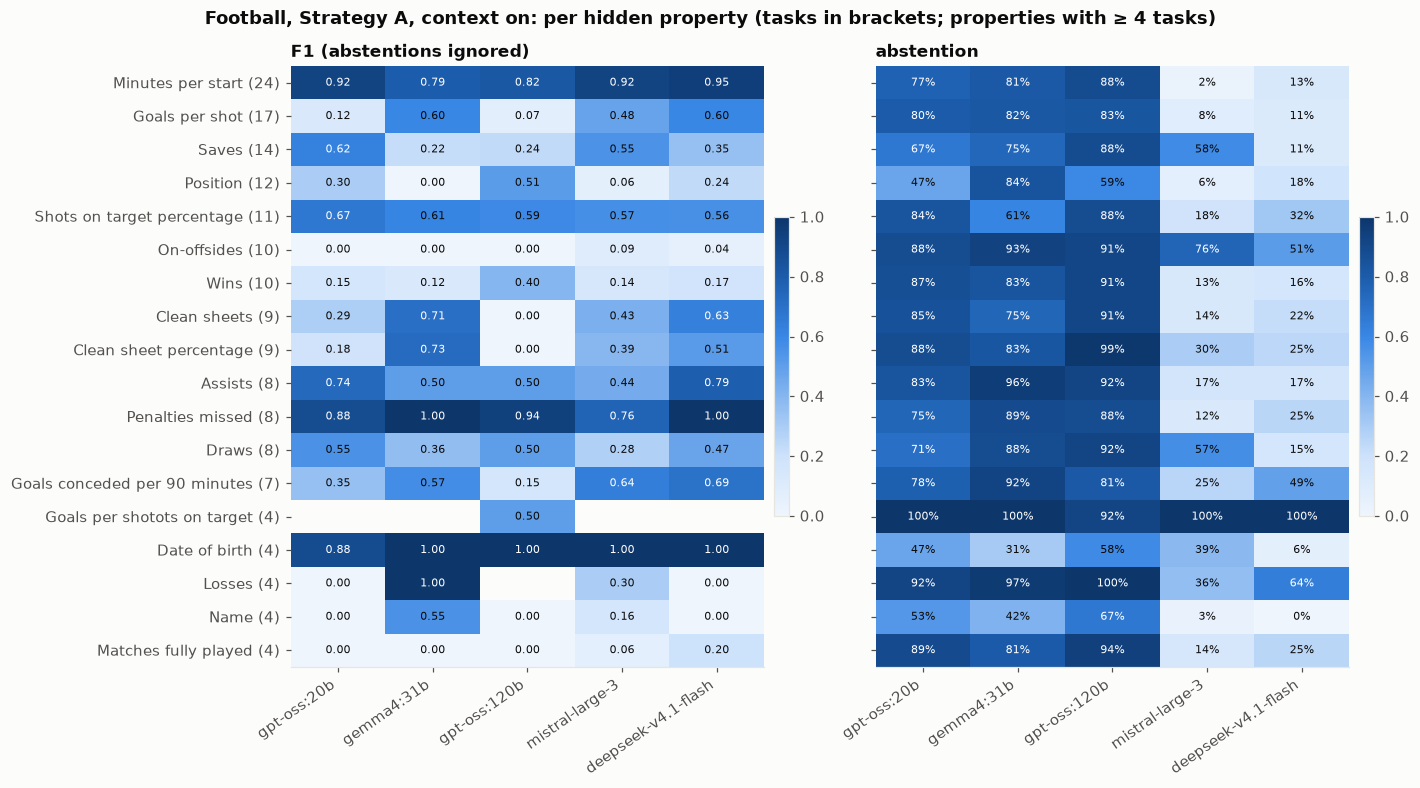

In [14]:
d = A[A.set == "ctx"]
t = metrics(d, ["property", "model"])
ntask = d.drop_duplicates("task_id").property.value_counts()
props = ntask[ntask >= 4].index.tolist()
pv = t[t.property.isin(props)].pivot(index="property", columns="model", values="f1_ign").reindex(index=props, columns=MODELS)
pa = t[t.property.isin(props)].pivot(index="property", columns="model", values="abstention").reindex(index=props, columns=MODELS)
fig, axes = plt.subplots(1, 2, figsize=(13, 0.32 * len(props) + 1.5))
heat(axes[0], pv, xlabels=MN, ylabels=[f"{p} ({ntask[p]})" for p in props]); axes[0].set_title("F1 (abstentions ignored)")
heat(axes[1], pa, fmt="{:.0%}", xlabels=MN, ylabels=[""] * len(props)); axes[1].set_title("abstention")
fig.suptitle("Football, Strategy A, context on: per hidden property (tasks in brackets; properties with ≥ 4 tasks)")
save(fig, FOLDER, "a_properties")

Per property, the scores separate guessable values from facts that need retrieval. *Minutes per start* (F1 ign 0.79–0.95), *Penalties missed* (0.76–1.00) and *Date of birth* (0.88–1.00 when answered) are mostly right. Answers to these tend to sit near a typical value (≈ 85 minutes, 0 penalties). *On-offsides* (≤ 0.09), *Matches fully played* (≤ 0.20) and *Name* (≤ 0.55) are almost never right. *Position* is 0.00–0.51 partly because of format: the ground truth uses codes ("GK", "DF,MF") and an answer like "Goalkeeper" fails the token-overlap test.

### Score against the popularity pop(p) of the hidden property

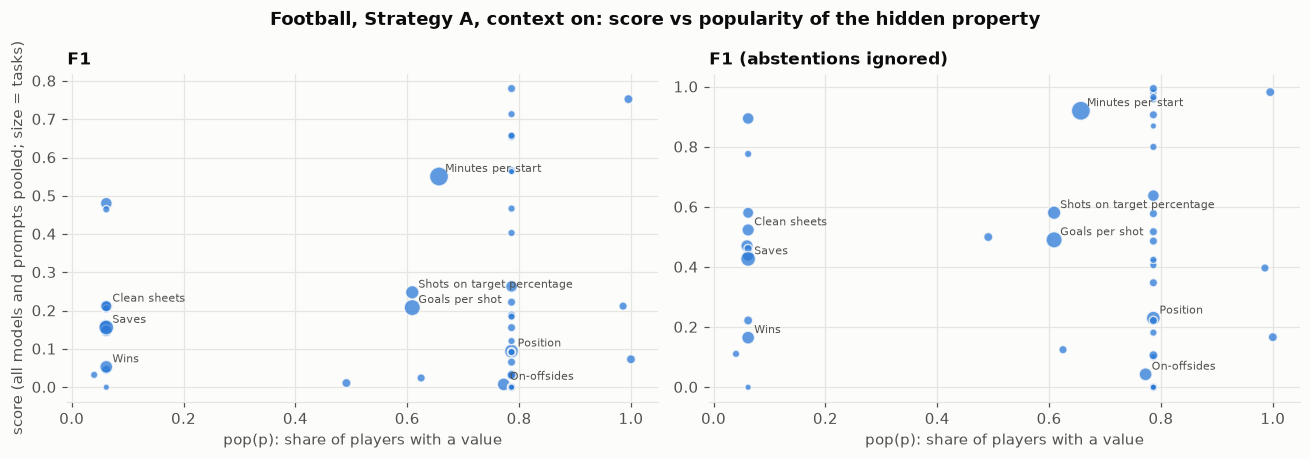

In [15]:
pop = popularity("football").set_index("property").popularity
d = A[A.set == "ctx"]
t = metrics(d, ["property"]).assign(pop=lambda x: x.property.map(pop), n=lambda x: x.tasks / 45)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (s, n) in zip(axes, SCORES):
    ax.scatter(t["pop"], t[s], s=12 + 6 * t.n, color=BLUE, alpha=0.75, edgecolor=SURFACE)
    for _, r in t.nlargest(8, "n").iterrows():
        ax.annotate(r.property, (r["pop"], r[s]), fontsize=7, color=INK2, xytext=(4, 3), textcoords="offset points")
    ax.set_xlabel("pop(p): share of players with a value"); ax.set_title(n)
axes[0].set_ylabel("score (all models and prompts pooled; size = tasks)")
fig.suptitle("Football, Strategy A, context on: score vs popularity of the hidden property")
save(fig, FOLDER, "a_popularity")

Unlike the strata, the popularity of the single property hardly predicts its score on football (Spearman ρ between pop(p) and F1 ≈ 0.04). Most football properties have pop(p) ≈ 0.79 (every outfield player has them) or ≈ 0.06 (goalkeeper statistics). Within each group, scores range from 0 to above 0.9, so what the property measures matters more than how common it is.

### How wrong are the wrong numbers?

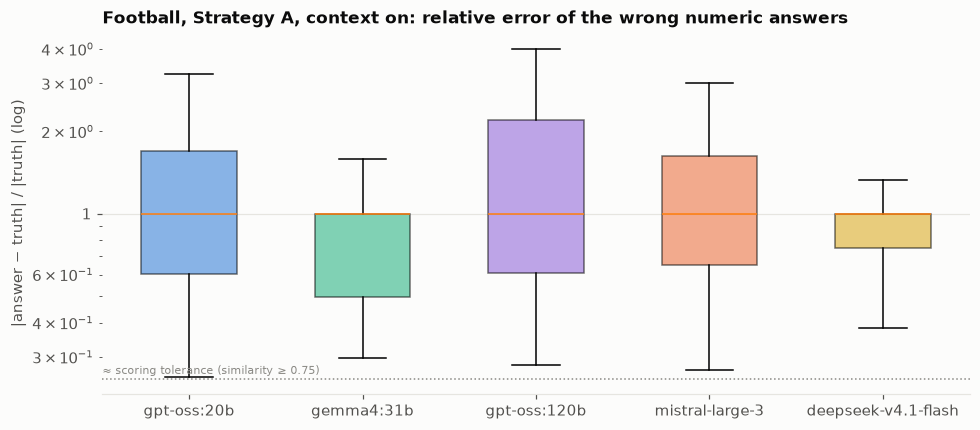

,count,25%,50%,75%
mname,,,,
deepseek-v4.1-flash,592.000,0.750,1.000,1.000
gemma4:31b,136.000,0.497,1.000,1.000
gpt-oss:120b,79.000,0.607,1.000,2.194
gpt-oss:20b,141.000,0.603,1.000,1.690
mistral-large-3,371.000,0.650,1.000,1.630


share of the wrong numeric answers that are 0: {'deepseek-v4.1-flash': 0.551, 'gemma4:31b': 0.301, 'gpt-oss:120b': 0.291, 'gpt-oss:20b': 0.234, 'mistral-large-3': 0.202}


In [16]:
d = A[A.set == "ctx"].copy()
d["rel_error"] = numeric_error(d)
d = d.dropna(subset=["rel_error"])
fig, ax = plt.subplots(figsize=(9, 4))
data = [d[d.model == m].rel_error.clip(1e-3, 1e3) for m in MODELS]
bp = ax.boxplot(data, tick_labels=MN, showfliers=False, patch_artist=True, widths=0.55)
for patch, m in zip(bp["boxes"], MODELS):
    patch.set_facecolor(MCOLOR[m]); patch.set_alpha(0.55)
logaxis(ax, "y"); ax.axhline(0.25, color=MUTED, ls=":", lw=1); ax.text(0.5, 0.26, "≈ scoring tolerance (similarity ≥ 0.75)", fontsize=7, color=MUTED)
ax.set_ylabel("|answer − truth| / |truth| (log)"); ax.grid(axis="x", visible=False)
ax.set_title("Football, Strategy A, context on: relative error of the wrong numeric answers")
save(fig, FOLDER, "a_numeric_error")
display(d.groupby("mname").rel_error.describe(percentiles=[0.25, 0.5, 0.75])[["count", "25%", "50%", "75%"]])
d["zero"] = pd.to_numeric(d.answer.str.strip('"'), errors="coerce") == 0
print("share of the wrong numeric answers that are 0:", d.groupby("mname").zero.mean().round(3).to_dict())

The wrong numeric answers are far off, not near misses: the median relative error is 1.0 for every model, and the interquartile range is about 0.5–2. A relative error of exactly 1 usually means the model answered 0 for a non-zero count. About a third of the wrong numeric answers of Strategy A are 0, so a default of 0 is a frequent failure, and the 0.75 tolerance already accepts every near miss.

## 5. Stability and effort

### Agreement of the 3 runs

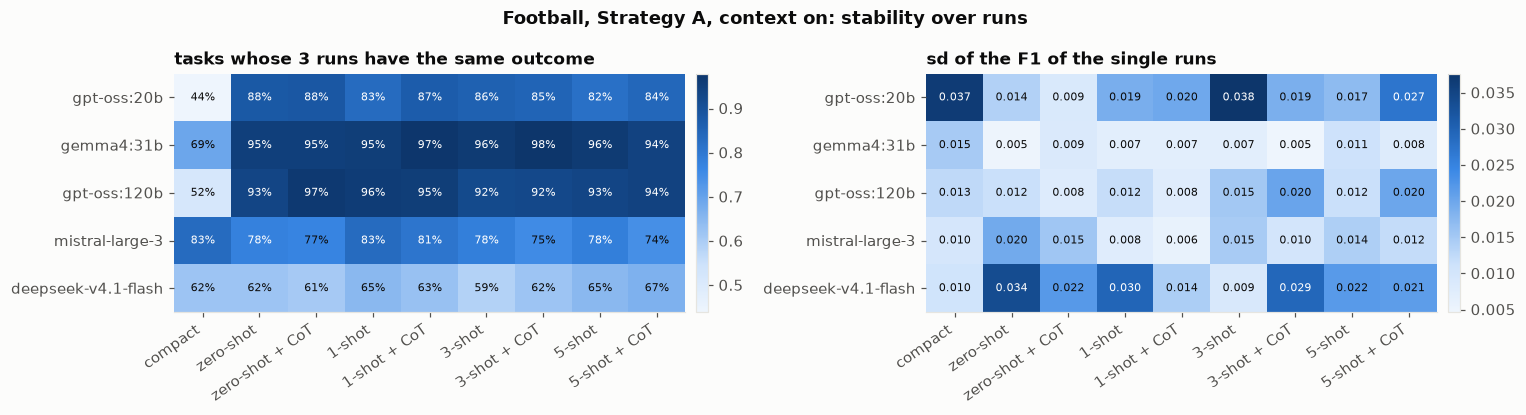

In [17]:
ag = agreement(runsA[runsA.set == "ctx"], ["model", "approach"])
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
heat(axes[0], ag.pivot(index="model", columns="approach", values="same outcome in all runs").reindex(index=MODELS, columns=PROMPTS),
     fmt="{:.0%}", xlabels=[PNAME[p] for p in PROMPTS], ylabels=MN)
axes[0].set_title("tasks whose 3 runs have the same outcome")
heat(axes[1], ag.pivot(index="model", columns="approach", values="f1_sd").reindex(index=MODELS, columns=PROMPTS),
     fmt="{:.3f}", xlabels=[PNAME[p] for p in PROMPTS], ylabels=MN)
axes[1].set_title("sd of the F1 of the single runs")
fig.suptitle("Football, Strategy A, context on: stability over runs")
save(fig, FOLDER, "a_stability")

With temperature 0.7, gemma4 and gpt-oss:120b give the same outcome in all 3 runs for 92–98% of the tasks under the long prompts, and deepseek only for 59–67%. The **compact** prompt is the least stable for the three cautious models (44–69%), because it is the prompt where they switch between answering and abstaining. The sd of the F1 of single runs stays below 0.04 everywhere, so the voted scores are robust.

### Energy, tokens and token amplification per prompt (context on)

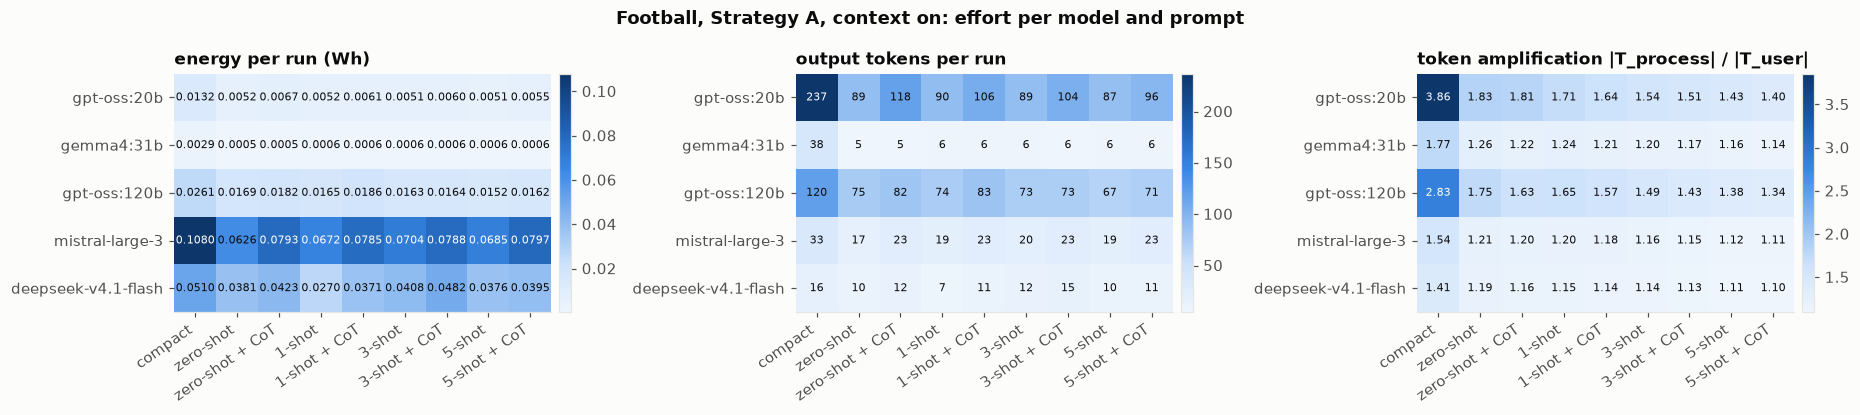

In [18]:
e = effA[effA.set == "ctx"].groupby(["model", "approach"]).agg(EC=("EC_run", "mean"), out=("tokens_out", "mean"), inn=("tokens_in", "mean"),
    proc=("tokens_proc", "sum"), user=("tokens_user", "sum"), lat=("latency_s", "mean")).reset_index()
e["amp"] = e.proc / e.user
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for ax, (c, n, f) in zip(axes, [("EC", "energy per run (Wh)", "{:.4f}"), ("out", "output tokens per run", "{:.0f}"), ("amp", "token amplification |T_process| / |T_user|", "{:.2f}")]):
    heat(ax, e.pivot(index="model", columns="approach", values=c).reindex(index=MODELS, columns=PROMPTS), fmt=f,
         xlabels=[PNAME[p] for p in PROMPTS], ylabels=MN); ax.set_title(n)
fig.suptitle("Football, Strategy A, context on: effort per model and prompt")
save(fig, FOLDER, "a_effort")

Energy per run varies 200-fold between models (gemma4 0.0005–0.003 Wh, mistral 0.06–0.11 Wh) and 1.5–6-fold between prompts of one model. **compact** is the most expensive prompt for every model, because it asks for an unconstrained answer and produces the longest output (gpt-oss:20b 237 tokens, 90% of them reasoning). Token amplification follows the same pattern, from 1.10× (deepseek, 5-shot + CoT) to 3.86× (gpt-oss:20b, compact). Longer prompts make amplification *smaller*, since the template counts as user tokens.

### Score against energy

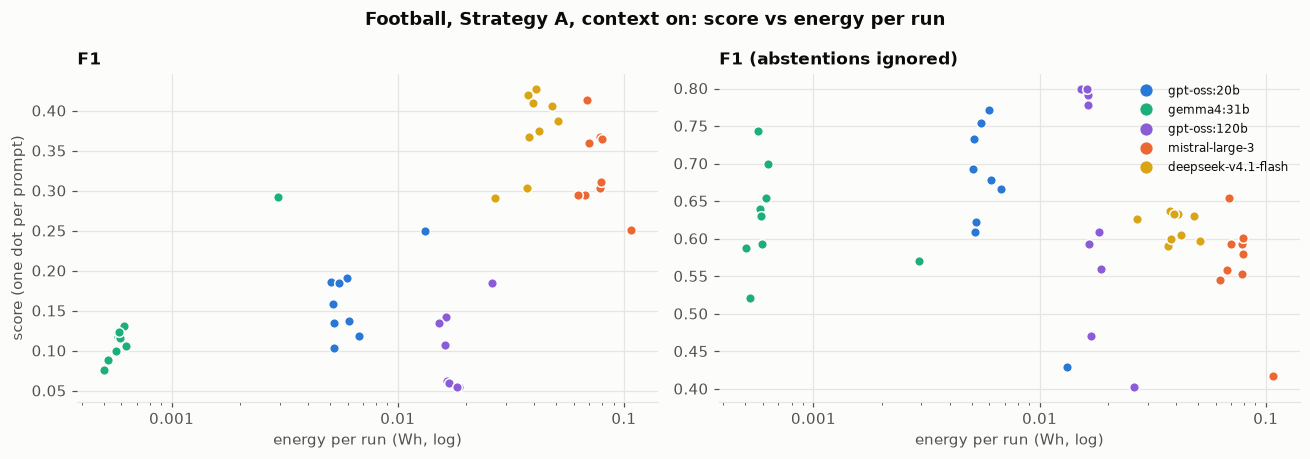

In [19]:
e = effA[effA.set == "ctx"].groupby(["model", "approach"]).EC_run.mean().rename("EC").reset_index()
t = metrics(A[A.set == "ctx"], ["model", "approach"]).merge(e, on=["model", "approach"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (s, n) in zip(axes, SCORES):
    for m in MODELS:
        d = t[t.model == m]
        ax.scatter(d.EC, d[s], color=MCOLOR[m], s=40, edgecolor=SURFACE, zorder=3)
    logaxis(ax, "x"); ax.set_xlabel("energy per run (Wh, log)"); ax.set_title(n)
axes[0].set_ylabel("score (one dot per prompt)"); axes[1].legend(handles=model_handles(), fontsize=8)
fig.suptitle("Football, Strategy A, context on: score vs energy per run")
save(fig, FOLDER, "a_energy_vs_f1")

Higher energy does not buy a higher F1 within a model: the dots of one colour lie side by side at nearly the same energy, and the most expensive prompt (compact) is the best F1 for three models only because it lowers abstention. Across models, the two high-recall models (mistral and deepseek) are also the most energy-hungry, but deepseek reaches the best F1 (0.43, 3-shot) at about 60% of the energy per run of mistral's best prompt.

## Takeaways

1. **Willingness to answer, not knowledge, separates the models on football.** F1 ranges from 0.11 to 0.38 (prompts pooled) while F1 ign stays within 0.57–0.62; three models abstain on 76–85% of the tasks.
2. **Examples help; CoT does not.** 3- and 5-shot are the best prompts on average; chain of thought gives no consistent gain. The compact prompt maximises F1 for cautious models by forcing answers, at the lowest precision.
3. **Context makes no measurable difference** on the 33 football pairs where it changes the given properties (ΔF1 +0.002, ΔF1 ign +0.018, both n.s.).
4. **The player's name is the strongest factor**: pooled F1 0.17 → 0.40 and F1 ign 0.44 → 0.70 in high-G tasks.
5. **The airports difficulty measure does not transfer.** Football difficulty is driven by which property is hidden (guessable typical values vs specific counts), not by pop(p) × centrality.
6. **Wrong numbers are far off** (median relative error 1.0), often a default 0; there are no near misses because the tolerance absorbs them.
7. **Energy differs 200× between models but buys little within a model**; compact is the most expensive prompt everywhere.